In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df=pd.read_csv('./Data/games.csv')
df.head(5)

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


In [3]:
df.columns

Index(['id', 'rated', 'created_at', 'last_move_at', 'turns', 'victory_status',
       'winner', 'increment_code', 'white_id', 'white_rating', 'black_id',
       'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_ply'],
      dtype='object')

In [4]:
df.shape

(20058, 16)

In [5]:
df.isna().sum()

id                0
rated             0
created_at        0
last_move_at      0
turns             0
victory_status    0
winner            0
increment_code    0
white_id          0
white_rating      0
black_id          0
black_rating      0
moves             0
opening_eco       0
opening_name      0
opening_ply       0
dtype: int64

In [6]:
df['victory_status']=df['victory_status'].str.replace('outoftime','timeout')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              20058 non-null  object 
 1   rated           20058 non-null  bool   
 2   created_at      20058 non-null  float64
 3   last_move_at    20058 non-null  float64
 4   turns           20058 non-null  int64  
 5   victory_status  20058 non-null  object 
 6   winner          20058 non-null  object 
 7   increment_code  20058 non-null  object 
 8   white_id        20058 non-null  object 
 9   white_rating    20058 non-null  int64  
 10  black_id        20058 non-null  object 
 11  black_rating    20058 non-null  int64  
 12  moves           20058 non-null  object 
 13  opening_eco     20058 non-null  object 
 14  opening_name    20058 non-null  object 
 15  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(9)
memory usage: 2.3+ MB


In [8]:
df.describe()

,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,1.483617e+12,1.483618e+12,60.465999,1596.631868,1588.831987,4.816981
std,2.850151e+10,2.850140e+10,33.570585,291.253376,291.036126,2.797152
min,1.376772e+12,1.376772e+12,1.000000,784.000000,789.000000,1.000000
25%,1.477548e+12,1.477548e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.496010e+12,1.496010e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.503170e+12,1.503170e+12,79.000000,1793.000000,1784.000000,6.000000
max,1.504493e+12,1.504494e+12,349.000000,2700.000000,2723.000000,28.000000


In [9]:
df.groupby('rated')[['id']].count()

,id
rated,
False,3903
True,16155


In [10]:
df.groupby('winner')[['id']].count()

,id
winner,
black,9107
draw,950
white,10001


# Visualizations

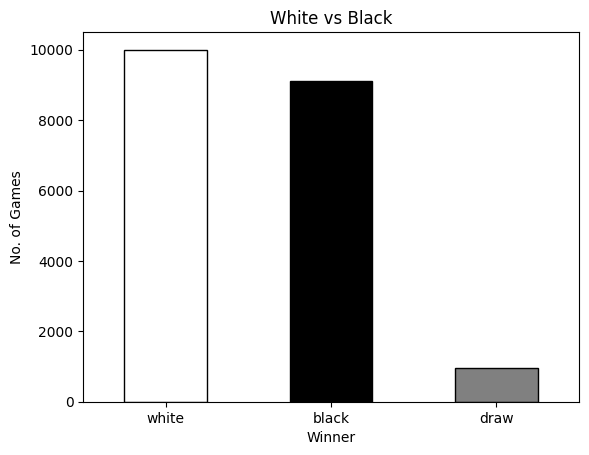

In [11]:
# 1. By Wins 

win_count=df['winner'].value_counts()
win_count.plot(kind='bar',color=['white','black','grey'],edgecolor='black')
plt.xlabel('Winner')
plt.ylabel('No. of Games')
plt.title('White vs Black')
plt.xticks(rotation=0)
plt.show()

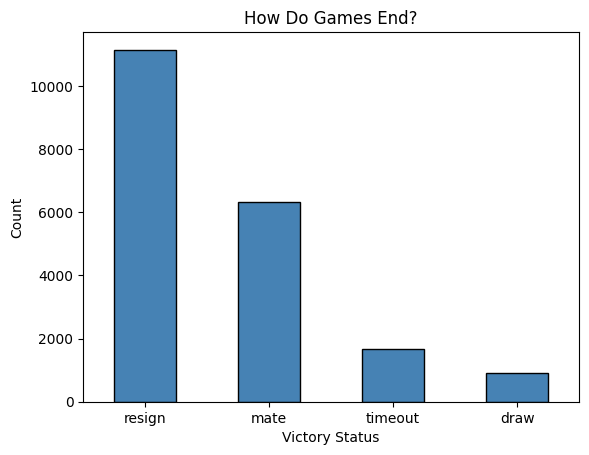

In [12]:
# 2. How do games end?
df['victory_status'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('How Do Games End?')
plt.xlabel('Victory Status')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

# The majority of games end by resignation or checkmate. 
# Timeouts are a less common but still notable way for games to conclude, highlighting the role of time management in the online format.

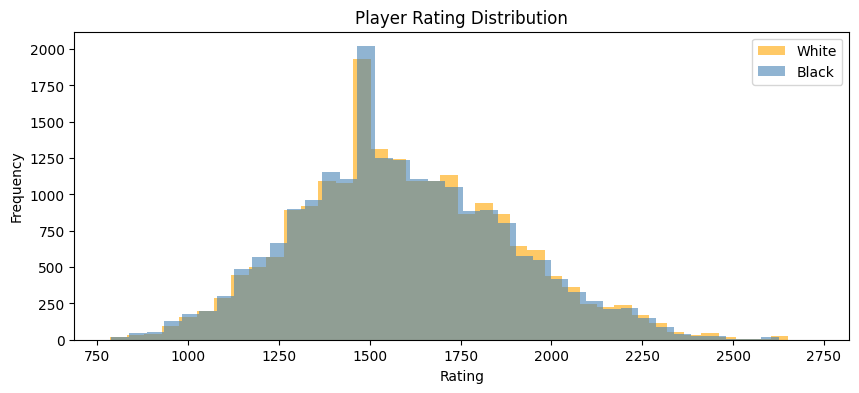

In [13]:
# 3. Rating distribution — both players
plt.figure(figsize=(10,4))
plt.hist(df['white_rating'], bins=40, alpha=0.6, label='White', color='orange')
plt.hist(df['black_rating'], bins=40, alpha=0.6, label='Black', color='steelblue')
plt.title('Player Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# The rating distributions of White and Black players are approximately bell-shaped and largely overlap, indicating similar rating distributions
# This means that, on average, there is no significant skill imbalance between players assigned to the white or black pieces on the Lichess platform.

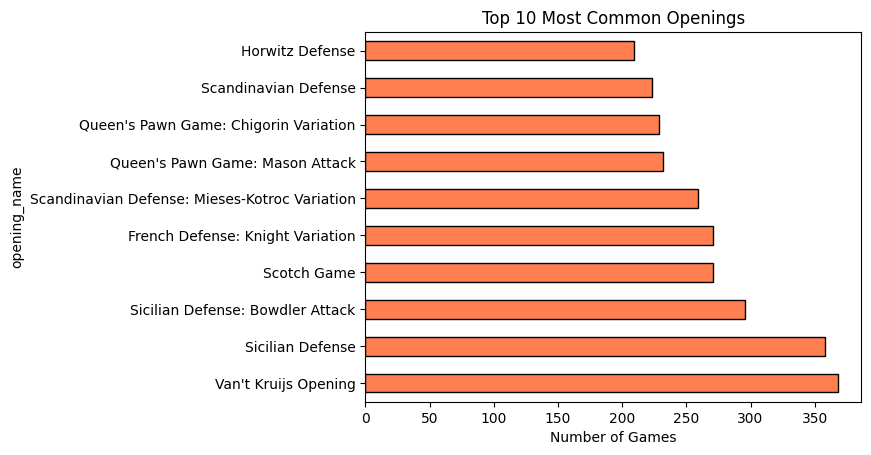

In [14]:
# 4. Most common openings (top 10)
top_openings = df['opening_name'].value_counts().head(10)
top_openings.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Top 10 Most Common Openings')
plt.xlabel('Number of Games')
plt.show()

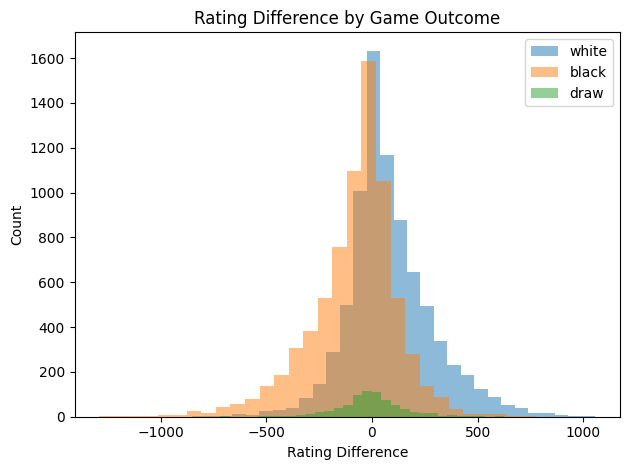

In [15]:
# 5. Does rating difference predict the winner?
df['rating_diff'] = df['white_rating'] - df['black_rating']
df_rated = df[df['rated'] == True]

for outcome in ['white', 'black', 'draw']:
    subset = df_rated[df_rated['winner'] == outcome]['rating_diff']
    plt.hist(subset, bins=30, alpha=0.5, label=outcome)

plt.title('Rating Difference by Game Outcome')
plt.xlabel('Rating Difference')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

# The distributions suggest that rating difference is associated with game outcome. 
# White wins are more common when the rating difference is positive, while Black wins are more common when it is negative.
# This visual evidence supports to use rating difference as a key feature in our model.

In [16]:
close_games = df[abs(df['white_rating'] - df['black_rating']) < 50]
close_games['winner'].value_counts(normalize=True)

winner
white    0.487832
black    0.458480
draw     0.053688
Name: proportion, dtype: float64

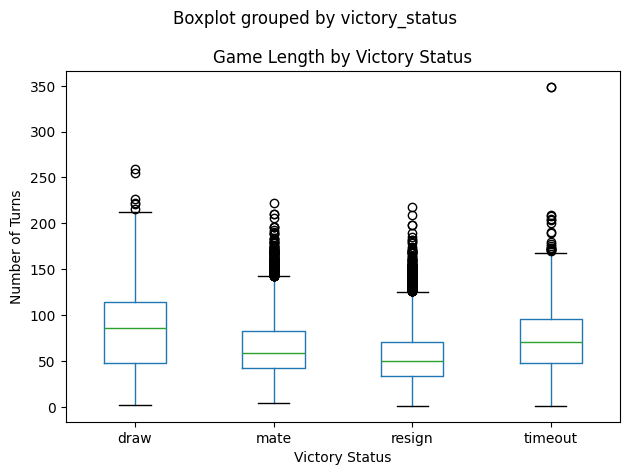

In [17]:
# Box plot: Turns by Victory Status
df.boxplot(column='turns', by='victory_status', grid=False)
plt.title('Game Length by Victory Status')
plt.xlabel('Victory Status')
plt.ylabel('Number of Turns')
plt.tight_layout()
plt.show()

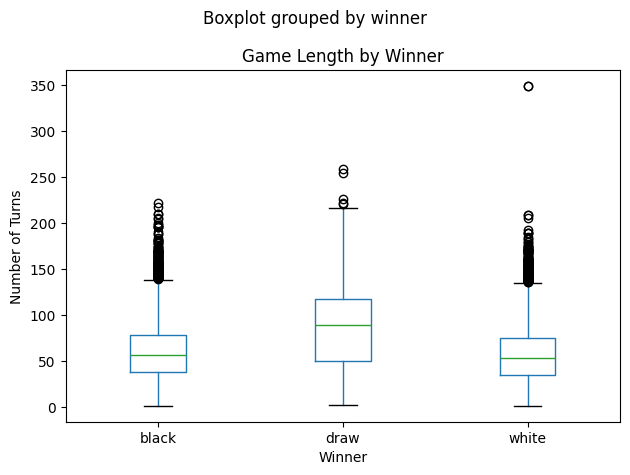

In [18]:
# Box plot: Turns by Winner
df.boxplot(column='turns', by='winner', grid=False)
plt.title('Game Length by Winner')
plt.xlabel('Winner')
plt.ylabel('Number of Turns')
plt.tight_layout()
plt.show()

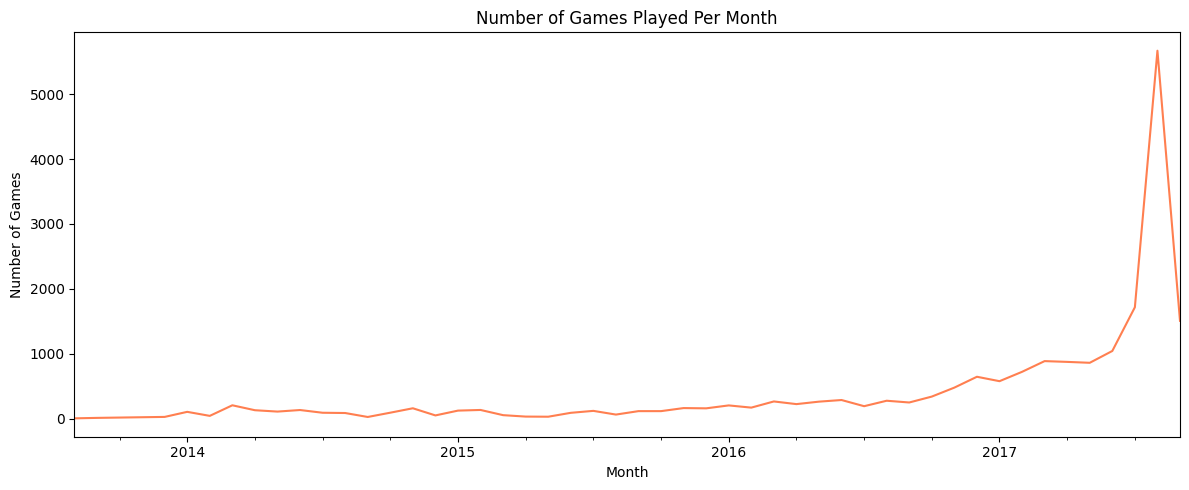

In [19]:
# Convert Unix timestamp to datetime
df['date'] = pd.to_datetime(df['created_at'], unit='ms')

# Extract year and month
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.to_period('M')

# Games per month
monthly_games = df.groupby('month').size()

plt.figure(figsize=(12, 5))
monthly_games.plot(kind='line', color='coral')
plt.title('Number of Games Played Per Month')
plt.xlabel('Month')
plt.ylabel('Number of Games')
plt.tight_layout()
plt.show()

# Model Selection, Training, Testing and Evaluation

In [20]:
cols_to_drop = [
    'id', 'created_at', 'last_move_at', 'white_id', 'black_id', 'victory_status', 'increment_code', 'moves', 
    'opening_eco', 'opening_name', 'turns', 'date', 'year', 'month', 'white_rating', 'black_rating'
]
df = df.drop(columns=cols_to_drop)
df['winner'] = df['winner'].map({'white':1,'black':0,'draw':2})
df = df[df['winner'] != 2]
df['rated']=df['rated'].astype('int')

# We remove the draw outcomes because of Data Imbalance, where draws are rare (only 950 games, or 4.7% of the dataset).
# Which may hinder the model training/learning.

# Also to clarify the Task. Removing them turns this into a binary classification problem (predicting a White or Black win). 
# This simplifies our analysis and allows us to focus on the primary question, what factors influence a decisive game?

In [21]:
# Testing the Impact of Collinear Features

# Our feature set includes white_rating, black_rating, and rating_diff. 
# These features are highly redundant because rating_diff is directly calculated from white_rating and black_rating.
# This creates strong dependence between the input features, which violates Naive Bayes's independence assumption and is redundant for Logistic Regression.

# To test whether these columns add any real value, we re-trained both models without white_rating & black_rating.
# Results:
#         - Logistic Regression: 64.76% → 64.78% 
#         - Gaussian Naive Bayes: 64.91% → 65.23%

# 1. Rating difference appears to provide useful predictive information.
# 2. Removing the redundant rating columns simplifies the feature set and produces slightly better results in this experiment.

# So, We drop white_rating and black_rating from the final feature set. It's simpler, conceptually cleaner, and performs at least as well.

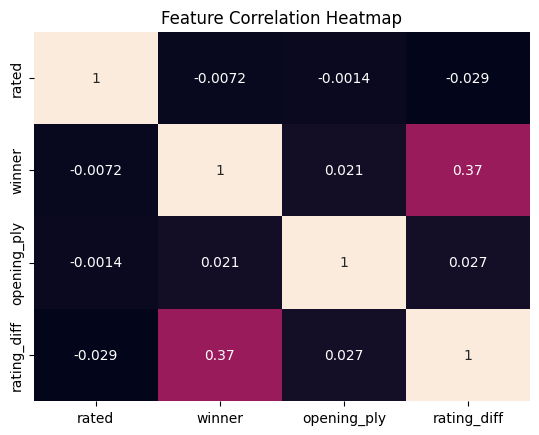

In [22]:
sns.heatmap(df.corr(),annot=True,cbar=False)
plt.title('Feature Correlation Heatmap')
plt.show()

In [23]:
X = df.drop(['winner'],axis=1)
y = df['winner']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_std = (X_train - mean)/std
X_test_std = (X_test - mean)/std

In [26]:
# Before we train our models, we need a baseline to measure their performance against. 
# A simple but strong baseline is to always predict the most frequent outcome.
# In non-draw games, White wins more often than Black. Let's calculate the exact baseline accuracy by always predicting that white wins.

baseline_accuracy = pd.Series(y_train).value_counts(normalize=True).max()
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")

Baseline Accuracy: 52.34%


# Logistic Regression

In [27]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_std,y_train)

LogisticRegression(max_iter=1000)

In [28]:
y_pred = model.predict(X_test_std)

In [29]:
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0]}).sort_values('coefficient', key=abs, ascending=False)
coef_df

,feature,coefficient
2,rating_diff,0.968868
1,opening_ply,0.028183
0,rated,0.010968


In [30]:
accuracy_score(y_test,y_pred)

0.6478283621140764

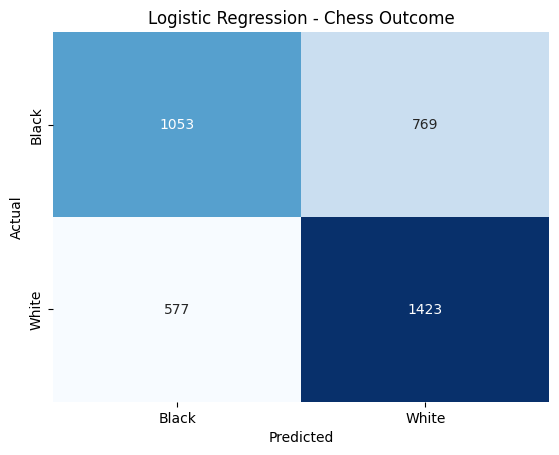

In [31]:
sns.heatmap(confusion_matrix(y_test,y_pred),fmt='d',annot=True,cmap='Blues',cbar=False,xticklabels=['Black', 'White'], yticklabels=['Black', 'White'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Chess Outcome')
plt.show()

In [32]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Black', 'White']
))

              precision    recall  f1-score   support

       Black       0.65      0.58      0.61      1822
       White       0.65      0.71      0.68      2000

    accuracy                           0.65      3822
   macro avg       0.65      0.64      0.64      3822
weighted avg       0.65      0.65      0.65      3822



# Gaussian Naive Bayes

In [33]:
# We train the Gaussian Naive Bayes model on the unscaled X_train data, unlike Logistic Regression. 
# This is because Naive Bayes is a probabilistic model that estimates the mean and variance of each feature independently. 
# Its calculations are not sensitive to feature scale. Therefore, standardizing the data provides no benefit and is unnecessary.

In [34]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_nb = gnb.predict(X_test)

In [35]:
accuracy_score(y_test, y_pred_nb)

0.652276295133438

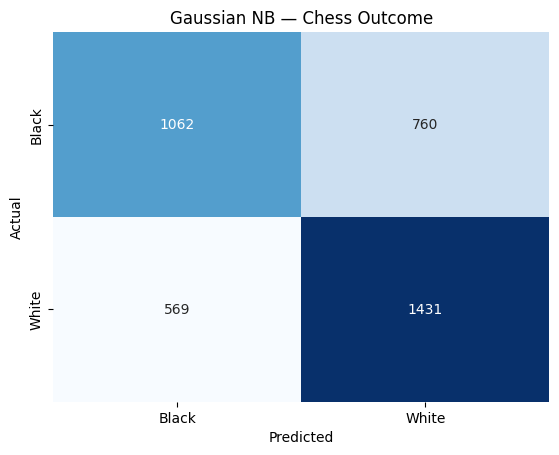

In [36]:
sns.heatmap(confusion_matrix(y_test, y_pred_nb), fmt='d', annot=True, cmap='Blues', cbar=False, xticklabels=['Black', 'White'], yticklabels=['Black', 'White'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian NB — Chess Outcome')
plt.show()

In [37]:
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Black', 'White']
))

              precision    recall  f1-score   support

       Black       0.65      0.58      0.62      1822
       White       0.65      0.72      0.68      2000

    accuracy                           0.65      3822
   macro avg       0.65      0.65      0.65      3822
weighted avg       0.65      0.65      0.65      3822



# Both models beat the 52.3% baseline. 
# Gaussian Naive Bayes slightly outperforms LR on this split, but the gap is small and likely noise. 